# Neural Networks From Scratch: TF-IDF MLP and Text CNN

Two neural classifiers built in PyTorch with no pretrained weights and no external data.

| Model | Input | Architecture |
| --- | --- | --- |
| MLP | TF-IDF vector (unigrams + bigrams) | Linear → ReLU → Dropout → Linear |
| Text CNN | Word and punctuation token IDs; the embedding table is learned from scratch | Embedding → parallel 1-D convolutions (widths 3, 4, 5) → max-pool over the passage → Dropout → Linear |


**Regularization:** dropout, weight decay (AdamW), early stopping, a capped vocabulary, and averaging several random seeds.

**To run:** select the project `.venv` kernel and run the cells from top to bottom

## 1. Environment and configuration

In [15]:
import itertools
import re
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
import torch.nn as nn
from IPython.display import display
from scipy.stats import rankdata
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split

# Run settings
QUICK_RUN = False          # True = fast check that everything runs (results not meaningful)
RANDOM_STATE = 42
N_SEEDS = 1 if QUICK_RUN else 3        # models averaged per architecture
MAX_EPOCHS = 2 if QUICK_RUN else 30    # upper bound
PATIENCE = 4                           # epochs without improvement before stopping
BATCH_SIZE = 64
RUN_GRID = not QUICK_RUN               # hyperparameter search for the MLP
MAKE_SUBMISSIONS = True                # retrain on all 10,000 datapoints?

# MLP Features & CNN size
MAX_FEATURES = 5000 if QUICK_RUN else 20000

MAX_VOCAB = 30000          # most frequent tokens kept; the rest map to <unk>
MIN_COUNT = 2              # tokens seen fewer times are treated as <unk>
MAX_LEN = 128 if QUICK_RUN else 400    # tokens per passage (~200 words on average)
EMB_DIM = 100
N_FILTERS = 64
KERNEL_SIZES = (3, 4, 5)


## AI used to make file robust:

# Locate the project whether Jupyter starts in the root or notebooks/.
PROJECT_ROOT = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "data" / "train.csv").is_file()
     and (folder / "data" / "test.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot find data/train.csv and data/test.csv. "
        "Start Jupyter from the project folder or its notebooks folder."
    )

DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

# Choose GPU
if torch.backends.mps.is_available():
    DEVICE = "mps"
elif torch.cuda.is_available():
    DEVICE = "cuda"
else:
    DEVICE = "cpu"

np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

print("Project root:", PROJECT_ROOT)
print("Device:", DEVICE, "| torch", torch.__version__)
print("QUICK_RUN:", QUICK_RUN)

Project root: /Users/hardbook/Documents/GitHub/Kaggle-Competition-AML
Device: mps | torch 2.15.0
QUICK_RUN: False


## 2. Load the data and the shared split

Rows are selected by `id` from the saved split files. The 8,000 training rows are then split 90/10 (stratified) into a fitting set and an inner-validation set used for early stopping.

In [16]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

train_ids = pd.read_csv(OUTPUT_DIR / "train_ids.csv")["id"]
val_ids = pd.read_csv(OUTPUT_DIR / "validation_ids.csv")["id"]

# Sanity checks on the split.
assert train["id"].is_unique, "Duplicate IDs in train.csv"
assert len(train_ids) == 8000 and len(val_ids) == 2000
assert not set(train_ids) & set(val_ids), "Train and validation IDs overlap"
assert set(train_ids) | set(val_ids) == set(train["id"]), "Split does not cover train.csv"

id_to_row = pd.Series(np.arange(len(train)), index=train["id"])
tr_rows = id_to_row.loc[train_ids].to_numpy()
va_rows = id_to_row.loc[val_ids].to_numpy()

text_all = train["text"].fillna("").to_numpy()
y_all = train["label"].to_numpy()
txt_test = test["text"].fillna("").to_numpy()

txt_tr, y_tr = text_all[tr_rows], y_all[tr_rows]
txt_va, y_va = text_all[va_rows], y_all[va_rows]

# Positions within the 8,000 training rows: fit the weights vs. early stopping.
fit_rows, stop_rows = train_test_split(
    np.arange(len(y_tr)),
    test_size=0.1,
    random_state=RANDOM_STATE,
    stratify=y_tr,
)

print(f"Fit: {len(fit_rows)} | Inner validation: {len(stop_rows)} | "
      f"Validation: {len(y_va)} | Test: {len(txt_test)}")

Fit: 7200 | Inner validation: 800 | Validation: 2000 | Test: 3000


## 3. Training utilities

One training loop serves both models. It minimizes binary cross-entropy with the AdamW optimizer, checks the inner-validation AUROC after every epoch, keeps the best weights, and stops after `PATIENCE` epochs without improvement.

In [17]:
def to_tensor(X, rows):
    # Return the selected rows of X as a tensor on DEVICE (sparse TF-IDF rows are densified per batch).
    chunk = X[rows]
    if sp.issparse(chunk):
        chunk = chunk.toarray()
    return torch.from_numpy(np.ascontiguousarray(chunk)).to(DEVICE)


def predict_proba(model, X, rows, batch_size=256):
    # Predicted probability of AI authorship for the given rows.
    model.eval()
    out = []
    with torch.no_grad():
        for s in range(0, len(rows), batch_size):
            logits = model(to_tensor(X, rows[s:s + batch_size]))
            out.append(torch.sigmoid(logits).float().cpu().numpy())
    return np.concatenate(out)


def make_monitor(X):
    # Inner-validation AUROC, used for early stopping and the hyperparameter search.
    return lambda model: roc_auc_score(y_tr[stop_rows], predict_proba(model, X, stop_rows))


def train_model(build, X, y, rows, epochs, lr, weight_decay, seed,
                batch_size=BATCH_SIZE, monitor=None, patience=PATIENCE):
    
    torch.manual_seed(seed)
    rng = np.random.RandomState(seed)
    model = build().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()

    history, best_auc, best_epoch, best_state, bad = [], -np.inf, epochs, None, 0
    for epoch in range(1, epochs + 1):
        model.train()
        order = rng.permutation(len(rows))
        total = 0.0
        for s in range(0, len(order), batch_size):
            b = rows[order[s:s + batch_size]]
            xb = to_tensor(X, b)
            yb = torch.tensor(y[b], dtype=torch.float32, device=DEVICE)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(b)

        record = {"epoch": epoch, "train_loss": total / len(rows)}
        if monitor is not None:
            auc = monitor(model)
            record["inner_val_auc"] = auc
            if auc > best_auc:
                best_auc, best_epoch, bad = auc, epoch, 0
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
        history.append(record)
        if monitor is not None and bad >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_epoch


def run_experiment(name, build, X_tr, X_va, hp, n_seeds=N_SEEDS):
    
    monitor = make_monitor(X_tr)
    all_tr, all_va = np.arange(len(y_tr)), np.arange(len(y_va))
    tr_p, va_p, best_epochs, histories = [], [], [], []
    start = time.perf_counter()
    for seed in range(n_seeds):
        model, hist, best_ep = train_model(
            build, X_tr, y_tr, fit_rows, MAX_EPOCHS, hp["lr"], hp["wd"],
            seed=seed, monitor=monitor,
        )
        tr_p.append(predict_proba(model, X_tr, all_tr))
        va_p.append(predict_proba(model, X_va, all_va))
        best_epochs.append(best_ep)
        histories.append(hist)
        print(f"{name} seed {seed}: best epoch {best_ep}, "
              f"inner-val AUROC {hist['inner_val_auc'].max():.4f}, "
              f"validation AUROC {roc_auc_score(y_va, va_p[-1]):.4f}")
    return {
        "name": name,
        "hp": hp,
        "train_probs": np.mean(tr_p, axis=0),
        "val_probs": np.mean(va_p, axis=0),
        "best_epochs": best_epochs,
        "histories": histories,
        "seconds": time.perf_counter() - start,
    }


def summarize(res):
    # Output: one results row
    train_auc = roc_auc_score(y_tr, res["train_probs"])
    val_auc = roc_auc_score(y_va, res["val_probs"])
    return {
        "model": res["name"],
        "train_auc": train_auc,
        "val_auc": val_auc,
        "auc_gap": train_auc - val_auc,
        "val_accuracy": accuracy_score(y_va, (res["val_probs"] >= 0.5).astype(int)),
        "training_time_seconds": res["seconds"],
    }

## 4. Model definitions

In [18]:
## Model 1: Tensor Flow-IDF MLP Vector
class TfidfMLP(nn.Module):
    # One hidden layer on top of the TF-IDF vector
    def __init__(self, in_dim, hidden, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


## Model 2: Text CNN
class TextCNN(nn.Module):
    # Learned word embeddings, convolutions over 3/4/5-token windows, max-pooled over the passage.
    def __init__(self, vocab_size, emb_dim=EMB_DIM, n_filters=N_FILTERS,
                 kernel_sizes=KERNEL_SIZES, dropout=0.5, emb_dropout=0.2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.emb_dropout = nn.Dropout(emb_dropout)
        self.convs = nn.ModuleList([nn.Conv1d(emb_dim, n_filters, k) for k in kernel_sizes])
        self.dropout = nn.Dropout(dropout)
        self.out = nn.Linear(n_filters * len(kernel_sizes), 1)

    def forward(self, x):
        e = self.emb_dropout(self.embedding(x)).transpose(1, 2)   # (batch, emb_dim, tokens)
        pooled = [torch.relu(conv(e)).max(dim=2).values for conv in self.convs]
        return self.out(self.dropout(torch.cat(pooled, dim=1))).squeeze(-1)

## 5. Model A: MLP on TF-IDF features

### 5.1 Features

The vectorizer is fit on the 8,000 training passages only. Each batch is converted from sparse to dense just before it goes into the network.

In [19]:
def make_tfidf():
    return TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=MAX_FEATURES,
        sublinear_tf=True,
        dtype=np.float32,
    )


tfidf = make_tfidf()
Xtf_tr = tfidf.fit_transform(txt_tr)
Xtf_va = tfidf.transform(txt_va)
print("TF-IDF features:", Xtf_tr.shape[1])

TF-IDF features: 20000


### 5.2 Hyperparameter search (model selection)

A small grid over hidden-layer size, dropout and weight decay, one seed each, scored on the inner-validation AUROC. The validation set is not used here.

In [20]:
mlp_hp = {"hidden": 256, "dropout": 0.5, "wd": 0.01, "lr": 1e-3}   # default if the grid is skipped

if RUN_GRID:
    grid_rows = []
    for hidden, dropout, wd in itertools.product([128, 512], [0.3, 0.6], [0.01, 0.1]):
        hp = {"hidden": hidden, "dropout": dropout, "wd": wd, "lr": 1e-3}
        build = lambda hp=hp: TfidfMLP(Xtf_tr.shape[1], hp["hidden"], hp["dropout"])
        _, hist, best_ep = train_model(
            build, Xtf_tr, y_tr, fit_rows, MAX_EPOCHS, hp["lr"], hp["wd"],
            seed=0, monitor=make_monitor(Xtf_tr),
        )
        grid_rows.append({**hp, "best_epoch": best_ep, "inner_val_auc": hist["inner_val_auc"].max()})
        print(hp, f"-> inner-val AUROC {grid_rows[-1]['inner_val_auc']:.4f}")

    grid = pd.DataFrame(grid_rows).sort_values("inner_val_auc", ascending=False).reset_index(drop=True)
    display(grid)
    grid.to_csv(OUTPUT_DIR / "nn_mlp_grid.csv", index=False)

    best = grid.iloc[0]
    mlp_hp = {"hidden": int(best["hidden"]), "dropout": float(best["dropout"]),
              "wd": float(best["wd"]), "lr": 1e-3}

print("MLP hyperparameters:", mlp_hp)

{'hidden': 128, 'dropout': 0.3, 'wd': 0.01, 'lr': 0.001} -> inner-val AUROC 0.9222
{'hidden': 128, 'dropout': 0.3, 'wd': 0.1, 'lr': 0.001} -> inner-val AUROC 0.9222
{'hidden': 128, 'dropout': 0.6, 'wd': 0.01, 'lr': 0.001} -> inner-val AUROC 0.9234
{'hidden': 128, 'dropout': 0.6, 'wd': 0.1, 'lr': 0.001} -> inner-val AUROC 0.9234
{'hidden': 512, 'dropout': 0.3, 'wd': 0.01, 'lr': 0.001} -> inner-val AUROC 0.9198
{'hidden': 512, 'dropout': 0.3, 'wd': 0.1, 'lr': 0.001} -> inner-val AUROC 0.9198
{'hidden': 512, 'dropout': 0.6, 'wd': 0.01, 'lr': 0.001} -> inner-val AUROC 0.9225
{'hidden': 512, 'dropout': 0.6, 'wd': 0.1, 'lr': 0.001} -> inner-val AUROC 0.9226


,hidden,dropout,wd,lr,best_epoch,inner_val_auc
0,128,0.6,0.10,0.001,4,0.923412
1,128,0.6,0.01,0.001,4,0.923375
2,512,0.6,0.10,0.001,2,0.922638
3,512,0.6,0.01,0.001,2,0.922531
4,128,0.3,0.01,0.001,3,0.922231
5,128,0.3,0.10,0.001,3,0.922169
6,512,0.3,0.01,0.001,1,0.919806
7,512,0.3,0.10,0.001,1,0.919800


MLP hyperparameters: {'hidden': 128, 'dropout': 0.6, 'wd': 0.1, 'lr': 0.001}


### 5.3 Train with several seeds

In [21]:
mlp_res = run_experiment(
    f"NN: TF-IDF MLP (hidden={mlp_hp['hidden']}, dropout={mlp_hp['dropout']}, wd={mlp_hp['wd']})",
    lambda: TfidfMLP(Xtf_tr.shape[1], mlp_hp["hidden"], mlp_hp["dropout"]),
    Xtf_tr, Xtf_va, mlp_hp,
)
display(pd.DataFrame([summarize(mlp_res)]))

NN: TF-IDF MLP (hidden=128, dropout=0.6, wd=0.1) seed 0: best epoch 4, inner-val AUROC 0.9234, validation AUROC 0.9392
NN: TF-IDF MLP (hidden=128, dropout=0.6, wd=0.1) seed 1: best epoch 3, inner-val AUROC 0.9230, validation AUROC 0.9394
NN: TF-IDF MLP (hidden=128, dropout=0.6, wd=0.1) seed 2: best epoch 3, inner-val AUROC 0.9246, validation AUROC 0.9400


,model,train_auc,val_auc,auc_gap,val_accuracy,training_time_seconds
0,"NN: TF-IDF MLP (hidden=128, dropout=0.6, wd=0.1)",0.99585,0.939891,0.055959,0.87,9.824717


## 6. Model B: Text CNN with embeddings learned from scratch

### 6.1 Tokenize and build the vocabulary

Text is lower-cased and split into words and punctuation marks (punctuation habits can differ between human and AI writing). The vocabulary comes from the 8,000 training passages only; ID 0 is padding and ID 1 is unknown. Passages are cut or padded to `MAX_LEN` tokens.

In [22]:
TOKEN_RE = re.compile(r"\w+|[^\w\s]")


def tokenize(text):
    return TOKEN_RE.findall(text.lower())


def build_vocab(texts, max_size=MAX_VOCAB, min_count=MIN_COUNT):
    counts = Counter(tok for t in texts for tok in tokenize(t))
    vocab = {"<pad>": 0, "<unk>": 1}
    for tok, c in counts.most_common(max_size - 2):
        if c < min_count:
            break
        vocab[tok] = len(vocab)
    return vocab


def encode(texts, vocab, max_len=MAX_LEN):
    out = np.zeros((len(texts), max_len), dtype=np.int64)
    for i, t in enumerate(texts):
        ids = [vocab.get(tok, 1) for tok in tokenize(t)[:max_len]]
        out[i, :len(ids)] = ids
    return out


vocab = build_vocab(txt_tr)
Xtok_tr = encode(txt_tr, vocab)
Xtok_va = encode(txt_va, vocab)

lengths = np.array([len(tokenize(t)) for t in txt_tr])
print("Vocabulary size:", len(vocab))
print(f"Tokens per passage: median {np.median(lengths):.0f}, "
      f"{(lengths > MAX_LEN).mean():.1%} of passages truncated at {MAX_LEN}")
print(f"Unknown-token rate in validation: {(Xtok_va == 1).sum() / (Xtok_va > 0).sum():.1%}")

Vocabulary size: 30000
Tokens per passage: median 249, 3.7% of passages truncated at 400
Unknown-token rate in validation: 2.8%


### 6.2 Train with several seeds

No grid search here because the CNN is slower to train; adjust `EMB_DIM`, `N_FILTERS`, or the dropout values in `TextCNN` if you want to experiment.

In [23]:
cnn_hp = {"lr": 1e-3, "wd": 0.01}

cnn_res = run_experiment(
    f"NN: Text CNN (emb={EMB_DIM}, filters={N_FILTERS}x{len(KERNEL_SIZES)}, max_len={MAX_LEN})",
    lambda: TextCNN(len(vocab)),
    Xtok_tr, Xtok_va, cnn_hp,
)
display(pd.DataFrame([summarize(cnn_res)]))

NN: Text CNN (emb=100, filters=64x3, max_len=400) seed 0: best epoch 11, inner-val AUROC 0.9255, validation AUROC 0.9411
NN: Text CNN (emb=100, filters=64x3, max_len=400) seed 1: best epoch 8, inner-val AUROC 0.9341, validation AUROC 0.9434
NN: Text CNN (emb=100, filters=64x3, max_len=400) seed 2: best epoch 13, inner-val AUROC 0.9323, validation AUROC 0.9434


,model,train_auc,val_auc,auc_gap,val_accuracy,training_time_seconds
0,"NN: Text CNN (emb=100, filters=64x3, max_len=400)",0.991238,0.948515,0.042723,0.8575,75.740072


## 7. Compare with the baseline

### 7.1 Results table and training curves

,model,train_auc,val_auc,auc_gap,val_accuracy,training_time_seconds
0,TF-IDF + Logistic Regression,0.993194,0.936066,0.057128,0.8670,2.363501
1,"NN: TF-IDF MLP (hidden=128, dropout=0.6, wd=0.1)",0.995850,0.939891,0.055959,0.8700,9.824717
2,"NN: Text CNN (emb=100, filters=64x3, max_len=400)",0.991238,0.948515,0.042723,0.8575,75.740072


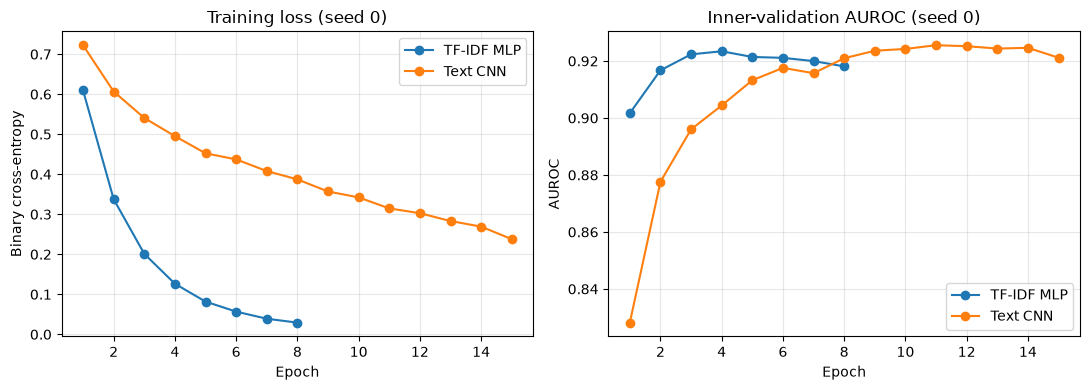

In [24]:
results = pd.DataFrame([summarize(mlp_res), summarize(cnn_res)])

baseline_path = OUTPUT_DIR / "baseline_results.csv"
comparison = pd.concat([pd.read_csv(baseline_path), results], ignore_index=True) if baseline_path.is_file() else results
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for res, label in [(mlp_res, "TF-IDF MLP"), (cnn_res, "Text CNN")]:
    h = res["histories"][0]
    axes[0].plot(h["epoch"], h["train_loss"], marker="o", label=label)
    axes[1].plot(h["epoch"], h["inner_val_auc"], marker="o", label=label)
axes[0].set(title="Training loss (seed 0)", xlabel="Epoch", ylabel="Binary cross-entropy")
axes[1].set(title="Inner-validation AUROC (seed 0)", xlabel="Epoch", ylabel="AUROC")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### 7.2 Do the models complement each other?

Rank-averages the validation predictions (AUROC depends only on ranking) and reports how correlated the models are. A blend that beats every single model, together with low correlation, means the models make different mistakes. With 2,000 validation passages, treat differences of about 0.01 or less as noise.

In [25]:
val_preds = {"MLP": mlp_res["val_probs"], "CNN": cnn_res["val_probs"]}

base_pred_path = OUTPUT_DIR / "baseline_validation_predictions.csv"
if base_pred_path.is_file():
    base = pd.read_csv(base_pred_path, usecols=["id", "predicted_probability"]).set_index("id")["predicted_probability"]
    val_preds = {"TF-IDF LR": base.loc[val_ids].to_numpy(), **val_preds}


def rank_blend(*preds):
    return np.mean([rankdata(p) for p in preds], axis=0) / len(preds[0])


blends = {"MLP + CNN": rank_blend(val_preds["MLP"], val_preds["CNN"])}
if "TF-IDF LR" in val_preds:
    blends["TF-IDF LR + MLP + CNN"] = rank_blend(*val_preds.values())

display(pd.DataFrame(
    [{"predictions": k, "val_auc": roc_auc_score(y_va, v)} for k, v in {**val_preds, **blends}.items()]
))
print("Rank correlation between models:")
display(pd.DataFrame({k: rankdata(v) for k, v in val_preds.items()}).corr().round(3))

,predictions,val_auc
0,TF-IDF LR,0.936066
1,MLP,0.939891
2,CNN,0.948515
3,MLP + CNN,0.960594
4,TF-IDF LR + MLP + CNN,0.956046


Rank correlation between models:


,TF-IDF LR,MLP,CNN
TF-IDF LR,1.000,0.971,0.859
MLP,0.971,1.000,0.842
CNN,0.859,0.842,1.000


## 8. Save results and validation predictions

Same column conventions as the baseline files, so any models can be compared or ensembled by joining on `id`.

In [26]:
results.to_csv(OUTPUT_DIR / "nn_results.csv", index=False)

for slug, res in [("nn_mlp", mlp_res), ("nn_cnn", cnn_res)]:
    pd.DataFrame({
        "id": val_ids.to_numpy(),
        "label": y_va,
        "predicted_probability": res["val_probs"],
        "predicted_label": (res["val_probs"] >= 0.5).astype(int),
    }).to_csv(OUTPUT_DIR / f"{slug}_validation_predictions.csv", index=False)

print("Saved nn_results.csv and validation predictions to", OUTPUT_DIR)

Saved nn_results.csv and validation predictions to /Users/hardbook/Documents/GitHub/Kaggle-Competition-AML/outputs


## 8.2: What do the results mean?

MLP model scores about the same as the baseline. Changing the weight decay does not affect model performance since number of epochs at which model stops improving is quite low. Dropout regularization has a larger impact.

CNN shows improvement with small overfitting gap and score of 0.1 above baseline. Correlation with baseline is 0.85 showing difference in model behavior. However, CNN accuracy is lower despite a higher AUROC.

MLP + CNN combination does best as the blend is an equal-weighted rank average

## 9. Kaggle submissions

Each model is retrained on all 10,000 labeled passages (features and vocabulary rebuilt on the full set) for the median number of epochs that early stopping chose, averaged over `N_SEEDS` seeds. Three files are written to `outputs/`: the MLP, the CNN, and their rank-average blend. Check the team's submission count before uploading (5 per day).

In [27]:
def save_submission(probs, filename):
    submission = pd.DataFrame({"id": test["id"], "label": probs})
    sample = pd.read_csv(DATA_DIR / "sample_submission.csv")
    assert len(submission) == 3000
    assert set(submission["id"]) == set(sample["id"])
    assert submission["label"].between(0, 1).all()
    submission.to_csv(OUTPUT_DIR / filename, index=False)
    print("Saved", OUTPUT_DIR / filename)


def refit_and_predict(build, X_full, X_test, hp, best_epochs):
    epochs = max(1, int(round(np.median(best_epochs))))
    all_rows, test_rows = np.arange(len(y_all)), np.arange(X_test.shape[0])
    probs = []
    for seed in range(N_SEEDS):
        model, _, _ = train_model(build, X_full, y_all, all_rows, epochs, hp["lr"], hp["wd"], seed=seed)
        probs.append(predict_proba(model, X_test, test_rows))
    print(f"Refit {N_SEEDS} seed(s) for {epochs} epochs")
    return np.mean(probs, axis=0)


if MAKE_SUBMISSIONS:
    # MLP: refit TF-IDF on all labeled text.
    tfidf_full = make_tfidf()
    Xtf_full = tfidf_full.fit_transform(text_all)
    Xtf_test = tfidf_full.transform(txt_test)
    mlp_test = refit_and_predict(
        lambda: TfidfMLP(Xtf_full.shape[1], mlp_hp["hidden"], mlp_hp["dropout"]),
        Xtf_full, Xtf_test, mlp_hp, mlp_res["best_epochs"],
    )
    save_submission(mlp_test, "submission_nn_mlp.csv")

    # CNN: rebuild the vocabulary on all labeled text.
    vocab_full = build_vocab(text_all)
    Xtok_full = encode(text_all, vocab_full)
    Xtok_test = encode(txt_test, vocab_full)
    cnn_test = refit_and_predict(
        lambda: TextCNN(len(vocab_full)),
        Xtok_full, Xtok_test, cnn_hp, cnn_res["best_epochs"],
    )
    save_submission(cnn_test, "submission_nn_cnn.csv")

    save_submission(rank_blend(mlp_test, cnn_test), "submission_nn_blend.csv")

Refit 3 seed(s) for 3 epochs
Saved /Users/hardbook/Documents/GitHub/Kaggle-Competition-AML/outputs/submission_nn_mlp.csv
Refit 3 seed(s) for 11 epochs
Saved /Users/hardbook/Documents/GitHub/Kaggle-Competition-AML/outputs/submission_nn_cnn.csv
Saved /Users/hardbook/Documents/GitHub/Kaggle-Competition-AML/outputs/submission_nn_blend.csv
